In [51]:
import os
import glob
import nilearn
import warnings
import numpy as np
import pandas as pd
import nibabel as nb
import pingouin as pg
import seaborn as sns
import os.path as path
import plotly.express as px
import statsmodels.api as sm
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler


In [52]:
demo = pd.read_csv('/Users/jivesh/Downloads/hbcd_state_factors.csv').set_index('States')
demo


,Population Density,Proficiency Scores,Unemployment Rate,Gini Coefficient,Childcare Cost Burden,Political Preferences,Tightness and Looseness,Incarceration Rate,Working Women Index,Women Peace Security Index,Women Legislator Representation,Abortion Laws,Reproductive Rights Index
States,,,,,,,,,,,,,
Alabama,101,251,2.5,0.477,18.5,1,75.45,394,10.31,0.238,17.1,5,1.41
Arkansas,59,251,3.1,0.474,4.0,1,75.03,596,24.58,0.231,23.0,5,0.73
California,250,251,4.7,0.487,3.7,0,27.27,246,82.96,0.564,36.7,1,6.22
Georgia,192,252,3.3,0.479,56.2,1,60.26,449,13.51,0.382,34.7,4,1.95
Illinois,226,259,4.5,0.481,10.7,0,45.95,235,74.03,0.602,41.2,1,4.13
Maryland,637,262,2.2,0.456,0.8,0,45.50,261,52.17,0.639,41.0,1,5.21
Massachusetts,898,267,3.5,0.488,3.4,0,35.12,96,68.83,0.709,30.5,2,3.87
Minnesota,72,274,2.8,0.454,4.9,0,47.84,152,65.43,0.606,37.8,1,3.89
Missouri,90,259,3.1,0.461,8.8,1,59.60,385,40.01,0.381,29.4,2,0.22


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


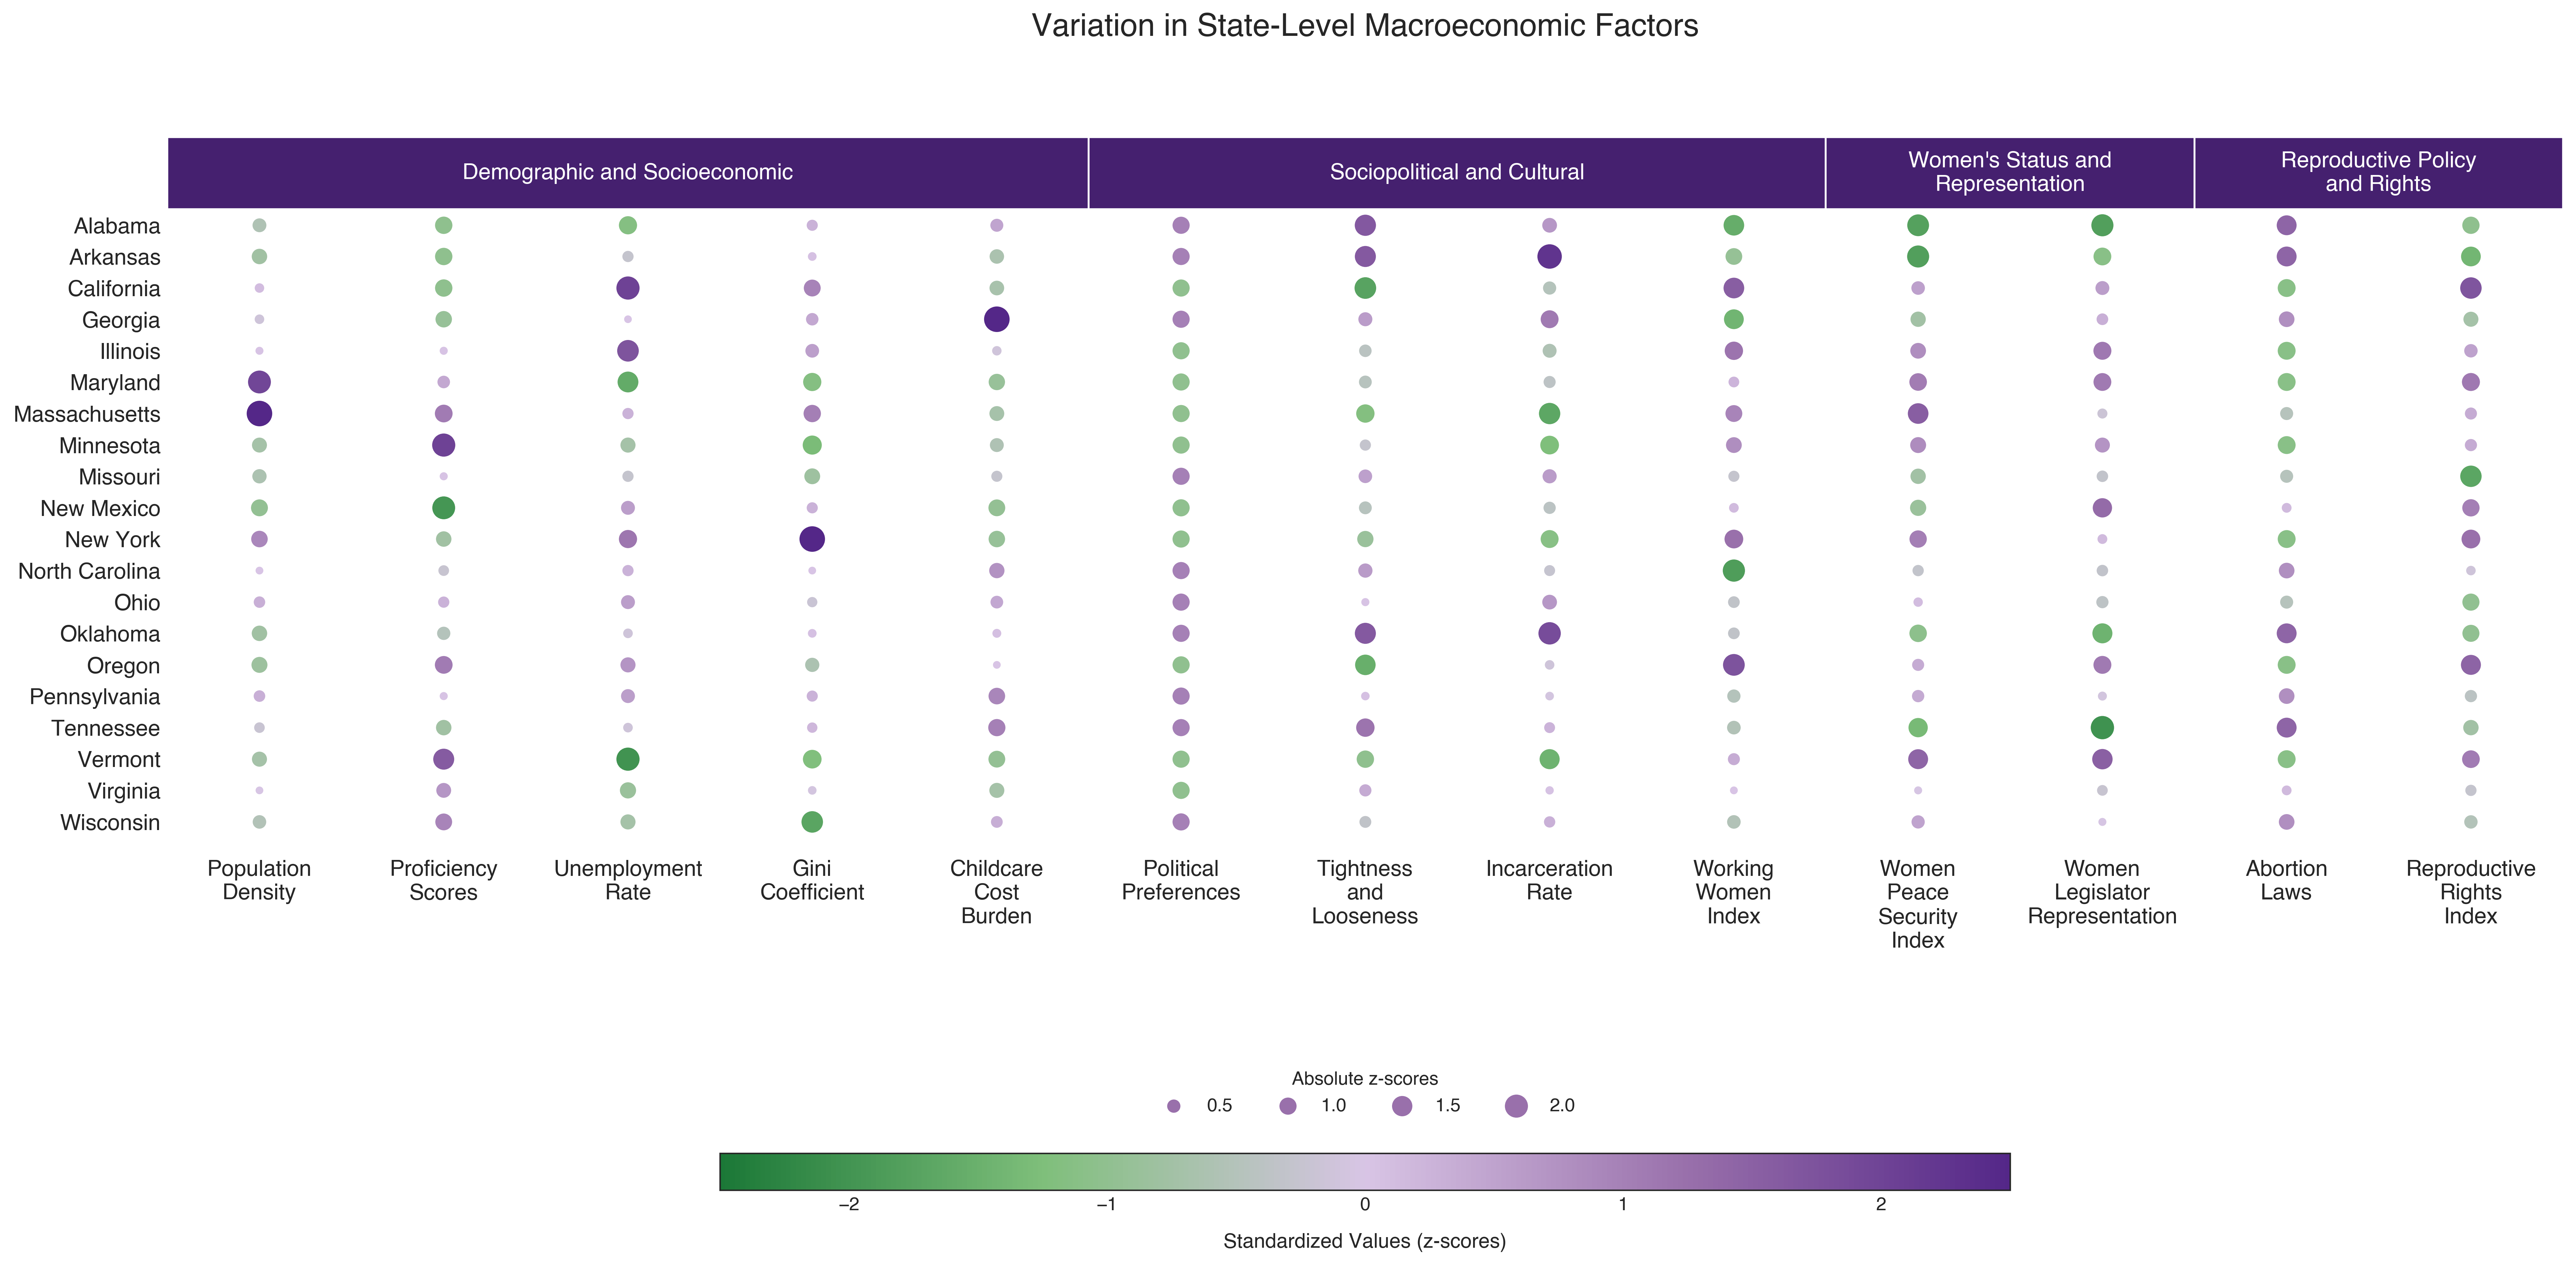

In [77]:
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# =====================================================
# 1. Define the 20 HBCD recruitment states
# =====================================================

states = [
    "Alabama", "Arkansas", "California", "Georgia",
    "Illinois", "Maryland", "Massachusetts", "Minnesota",
    "Missouri", "New Mexico", "New York", "North Carolina",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
    "Tennessee", "Vermont", "Virginia", "Wisconsin"
]

# =====================================================
# 2. Define the four domains and 13 factors
# =====================================================

domains = {
    "Demographic and Socioeconomic": [
        "Population Density",
        "Proficiency Scores",
        "Unemployment Rate",
        "Gini Coefficient",
        "Childcare Cost Burden"
    ],

    "Sociopolitical and Cultural": [
        "Political Preferences",
        "Tightness and Looseness",
        "Incarceration Rate",
        "Working Women Index"
    ],

    "Women's Status and\nRepresentation": [
        "Women Peace Security Index",
        "Women Legislator Representation"
    ],

    "Reproductive Policy\nand Rights": [
        "Abortion Laws",
        "Reproductive Rights Index"
    ]
}

factors = [
    factor
    for domain_factors in domains.values()
    for factor in domain_factors
]

# =====================================================
# 3. Prepare and standardize data
# =====================================================

# Assumes demo has state names as its index
heatmap_data = demo.loc[states, factors].astype(float)

# Standardize each factor across states
means = heatmap_data.mean(axis=0)
stds = heatmap_data.std(axis=0, ddof=0)

# Avoid division by zero for constant variables
stds = stds.replace(0, np.nan)

heatmap_z = (heatmap_data - means) / stds

# =====================================================
# 4. Figure settings
# =====================================================

plt.rcParams.update({
    "font.family": "Helvetica",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(22, 13))

# =====================================================
# 5. Custom Green–Lavender–Purple palette
# =====================================================

cmap = LinearSegmentedColormap.from_list(
    "GreenLavenderPurple",
    [
        "#1B7837",  # Dark green
        "#7FBF7B",  # Light green
        "#D8C5E5",  # Lavender midpoint
        "#9970AB",  # Medium purple
        "#542788"   # Dark purple
    ],
    N=256
)

cmap.set_bad("#E0E0E0")

norm = TwoSlopeNorm(
    vmin=-2.5,
    vcenter=0,
    vmax=2.5
)

n_states, n_factors = heatmap_z.shape

# =====================================================
# 6. Draw circle heatmap
# =====================================================

for i in range(n_states):

    for j in range(n_factors):

        z = heatmap_z.iloc[i, j]

        if pd.isna(z):
            continue

        # Clip values to the color range
        z_clipped = np.clip(z, -2.5, 2.5)

        # Smaller circles to prevent overlap
        circle_size = (
            20 + 180 * min(abs(z) / 2.5, 1)
        )

        ax.scatter(
            j + 0.5,
            i + 0.5,
            s=circle_size,
            color=cmap(norm(z_clipped)),
            edgecolors="#FFFFFF",
            linewidths=0.3,
            zorder=3
        )

# =====================================================
# 7. Format axes
# =====================================================

ax.set_xlim(0, n_factors)
ax.set_ylim(n_states, -2.3)

ax.set_xticks(np.arange(n_factors) + 0.5)
ax.set_yticks(np.arange(n_states) + 0.5)

# Wrap factor names onto multiple lines
ax.set_xticklabels(
    [factor.replace(" ", "\n") for factor in factors],
    fontsize=12,
    rotation=0,
    ha="center"
)

ax.set_yticklabels(
    states,
    fontsize=12,
    rotation=0
)

ax.tick_params(
    axis="both",
    length=0
)

ax.tick_params(
    axis="x",
    pad=12
)

ax.set_xlabel("")
ax.set_ylabel("")

# =====================================================
# 8. Add four purple domain headers
# =====================================================

header_colors = ["#45206F"] * 4

start = 0

for (domain, domain_factors), color in zip(
    domains.items(), header_colors
):

    width = len(domain_factors)

    # Domain header rectangle
    rect = Rectangle(
        (start, -2.3),
        width,
        2.3,
        facecolor=color,
        edgecolor="white",
        linewidth=1,
        clip_on=False,
        zorder=5
    )

    ax.add_patch(rect)

    # Domain label
    ax.text(
        start + width / 2,
        -1.15,
        domain,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white",
        zorder=6
    )

    start += width

# =====================================================
# 9. Add horizontal colorbar
# =====================================================

sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    fraction=0.035,
    pad=0.30,
    shrink=0.55,
    aspect=35
)

cbar.set_ticks([-2, -1, 0, 1, 2])

cbar.set_label(
    "Standardized Values (z-scores)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=10,
    length=0
)

# =====================================================
# 10. Add circle size legend
# =====================================================

legend_values = [0.5, 1.0, 1.5, 2.0]

legend_handles = []

for value in legend_values:

    size = 20 + 180 * min(value / 2.5, 1)

    handle = ax.scatter(
        [],
        [],
        s=size,
        facecolor="#9970AB",
        edgecolor="white",
        linewidth=0.3,
        label=f"{value:.1f}"
    )

    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title="Absolute z-scores",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.31),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=10
)

# =====================================================
# 11. Final formatting
# =====================================================

ax.set_title(
    "Variation in State-Level Macroeconomic Factors",
    fontsize=17,
    fontweight="bold",
    pad=55
)

fig.subplots_adjust(
    top=0.85,
    bottom=0.24,
    left=0.15,
    right=0.97
)

# =====================================================
# 12. Save figures
# =====================================================

plt.savefig(
    "HBCD_Circle_Heatmap_GreenLavenderPurple.png",
    dpi=1000,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "HBCD_Circle_Heatmap_GreenLavenderPurple.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [53]:
%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

corr = demo.corr(method="pearson")

pvals = pd.DataFrame(
    np.zeros_like(corr),
    index=corr.index,
    columns=corr.columns
)

for i in range(len(demo.columns)):
    for j in range(len(demo.columns)):
        x = demo.iloc[:, i]
        y = demo.iloc[:, j]

        # Remove missing values pairwise
        valid = x.notna() & y.notna()

        rho, p = spearmanr(x[valid], y[valid])

        pvals.iloc[i, j] = p


# -----------------------------
# Significance function
# -----------------------------
def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


# -----------------------------
# Mask upper triangle + diagonal
# -----------------------------
mask = np.triu(
    np.ones_like(corr, dtype=bool),
    k=0
)


# -----------------------------
# Plot
# -----------------------------
plt.rcParams["font.family"] = "Helvetica"

fig, ax = plt.subplots(figsize=(10, 10), dpi=600)

sns.heatmap(
    corr,
    mask=mask,
    cmap="PRGn_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson r",
        "shrink": 0.55,
        "aspect": 25
    },
    ax=ax
)


# -----------------------------
# Add stars ABOVE rho values
# -----------------------------
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):

        if not mask[i, j]:

            rho = corr.iloc[i, j]
            stars = significance_stars(pvals.iloc[i, j])

            # Significance stars
            if stars:
                ax.text(
                    j + 0.50,
                    i + 0.36,
                    stars,
                    ha="center",
                    va="center",
                    fontsize=10,
                    fontweight="bold"
                )

            # Spearman rho
            ax.text(
                j + 0.50,
                i + 0.62,
                f"{rho:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )


plt.tight_layout()

fig.savefig(
    "correlation_matrix.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Number of states: 20
Number of variables: 13

PCA SUMMARY
      PC  Eigenvalue  Variance Explained (%)  Cumulative Variance (%)
0    PC1        7.33                   53.55                    53.55
1    PC2        2.33                   17.03                    70.58
2    PC3        1.26                    9.20                    79.78
3    PC4        0.98                    7.15                    86.93
4    PC5        0.61                    4.42                    91.35
5    PC6        0.35                    2.59                    93.94
6    PC7        0.24                    1.74                    95.68
7    PC8        0.22                    1.62                    97.30
8    PC9        0.13                    0.95                    98.25
9   PC10        0.12                    0.86                    99.11
10  PC11        0.07                    0.48                    99.59
11  PC12        0.04                    0.30                    99.89
12  PC13        0.02            

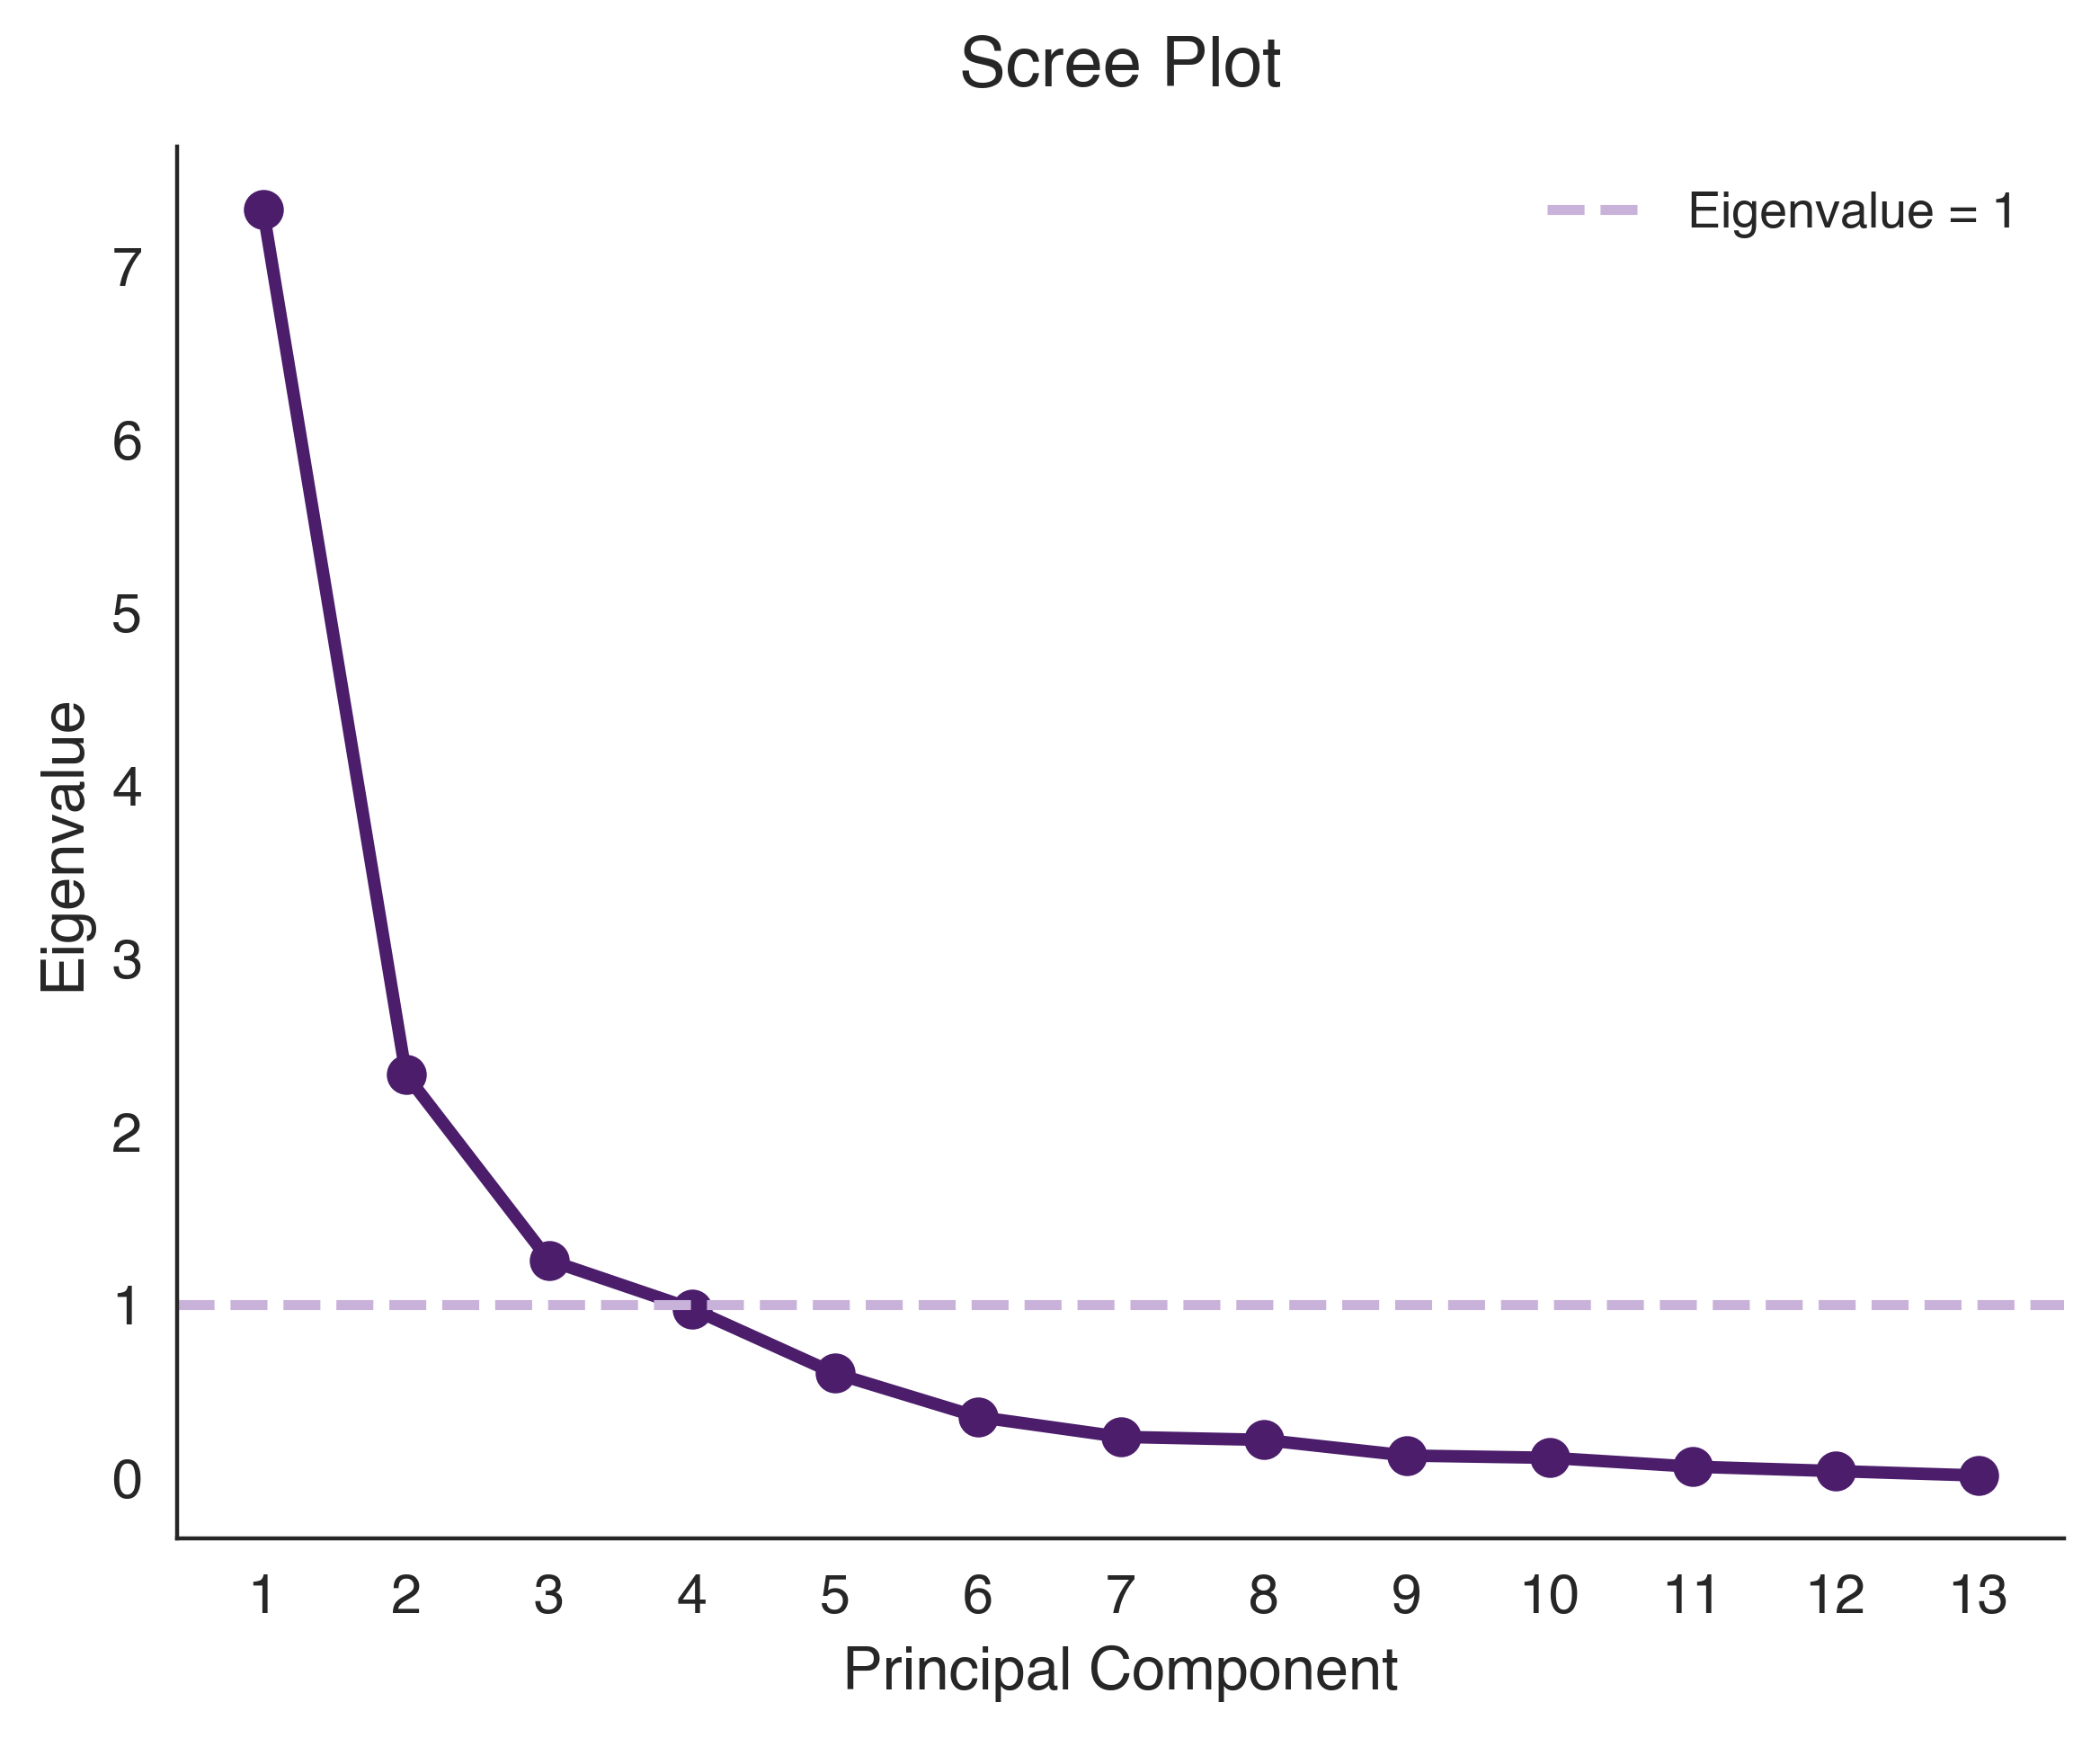


PARALLEL ANALYSIS
      PC  Observed  Random Mean  Random 95th  Retain (Mean)  Retain (95th)
0    PC1     7.328        2.799        3.268           True           True
1    PC2     2.331        2.257        2.565           True          False
2    PC3     1.259        1.873        2.121          False          False
3    PC4     0.979        1.559        1.769          False          False
4    PC5     0.605        1.293        1.479          False          False
5    PC6     0.354        1.058        1.230          False          False
6    PC7     0.238        0.848        1.009          False          False
7    PC8     0.221        0.665        0.814          False          False
8    PC9     0.130        0.505        0.641          False          False
9   PC10     0.117        0.365        0.486          False          False
10  PC11     0.066        0.246        0.348          False          False
11  PC12     0.041        0.148        0.230          False          False
12  PC

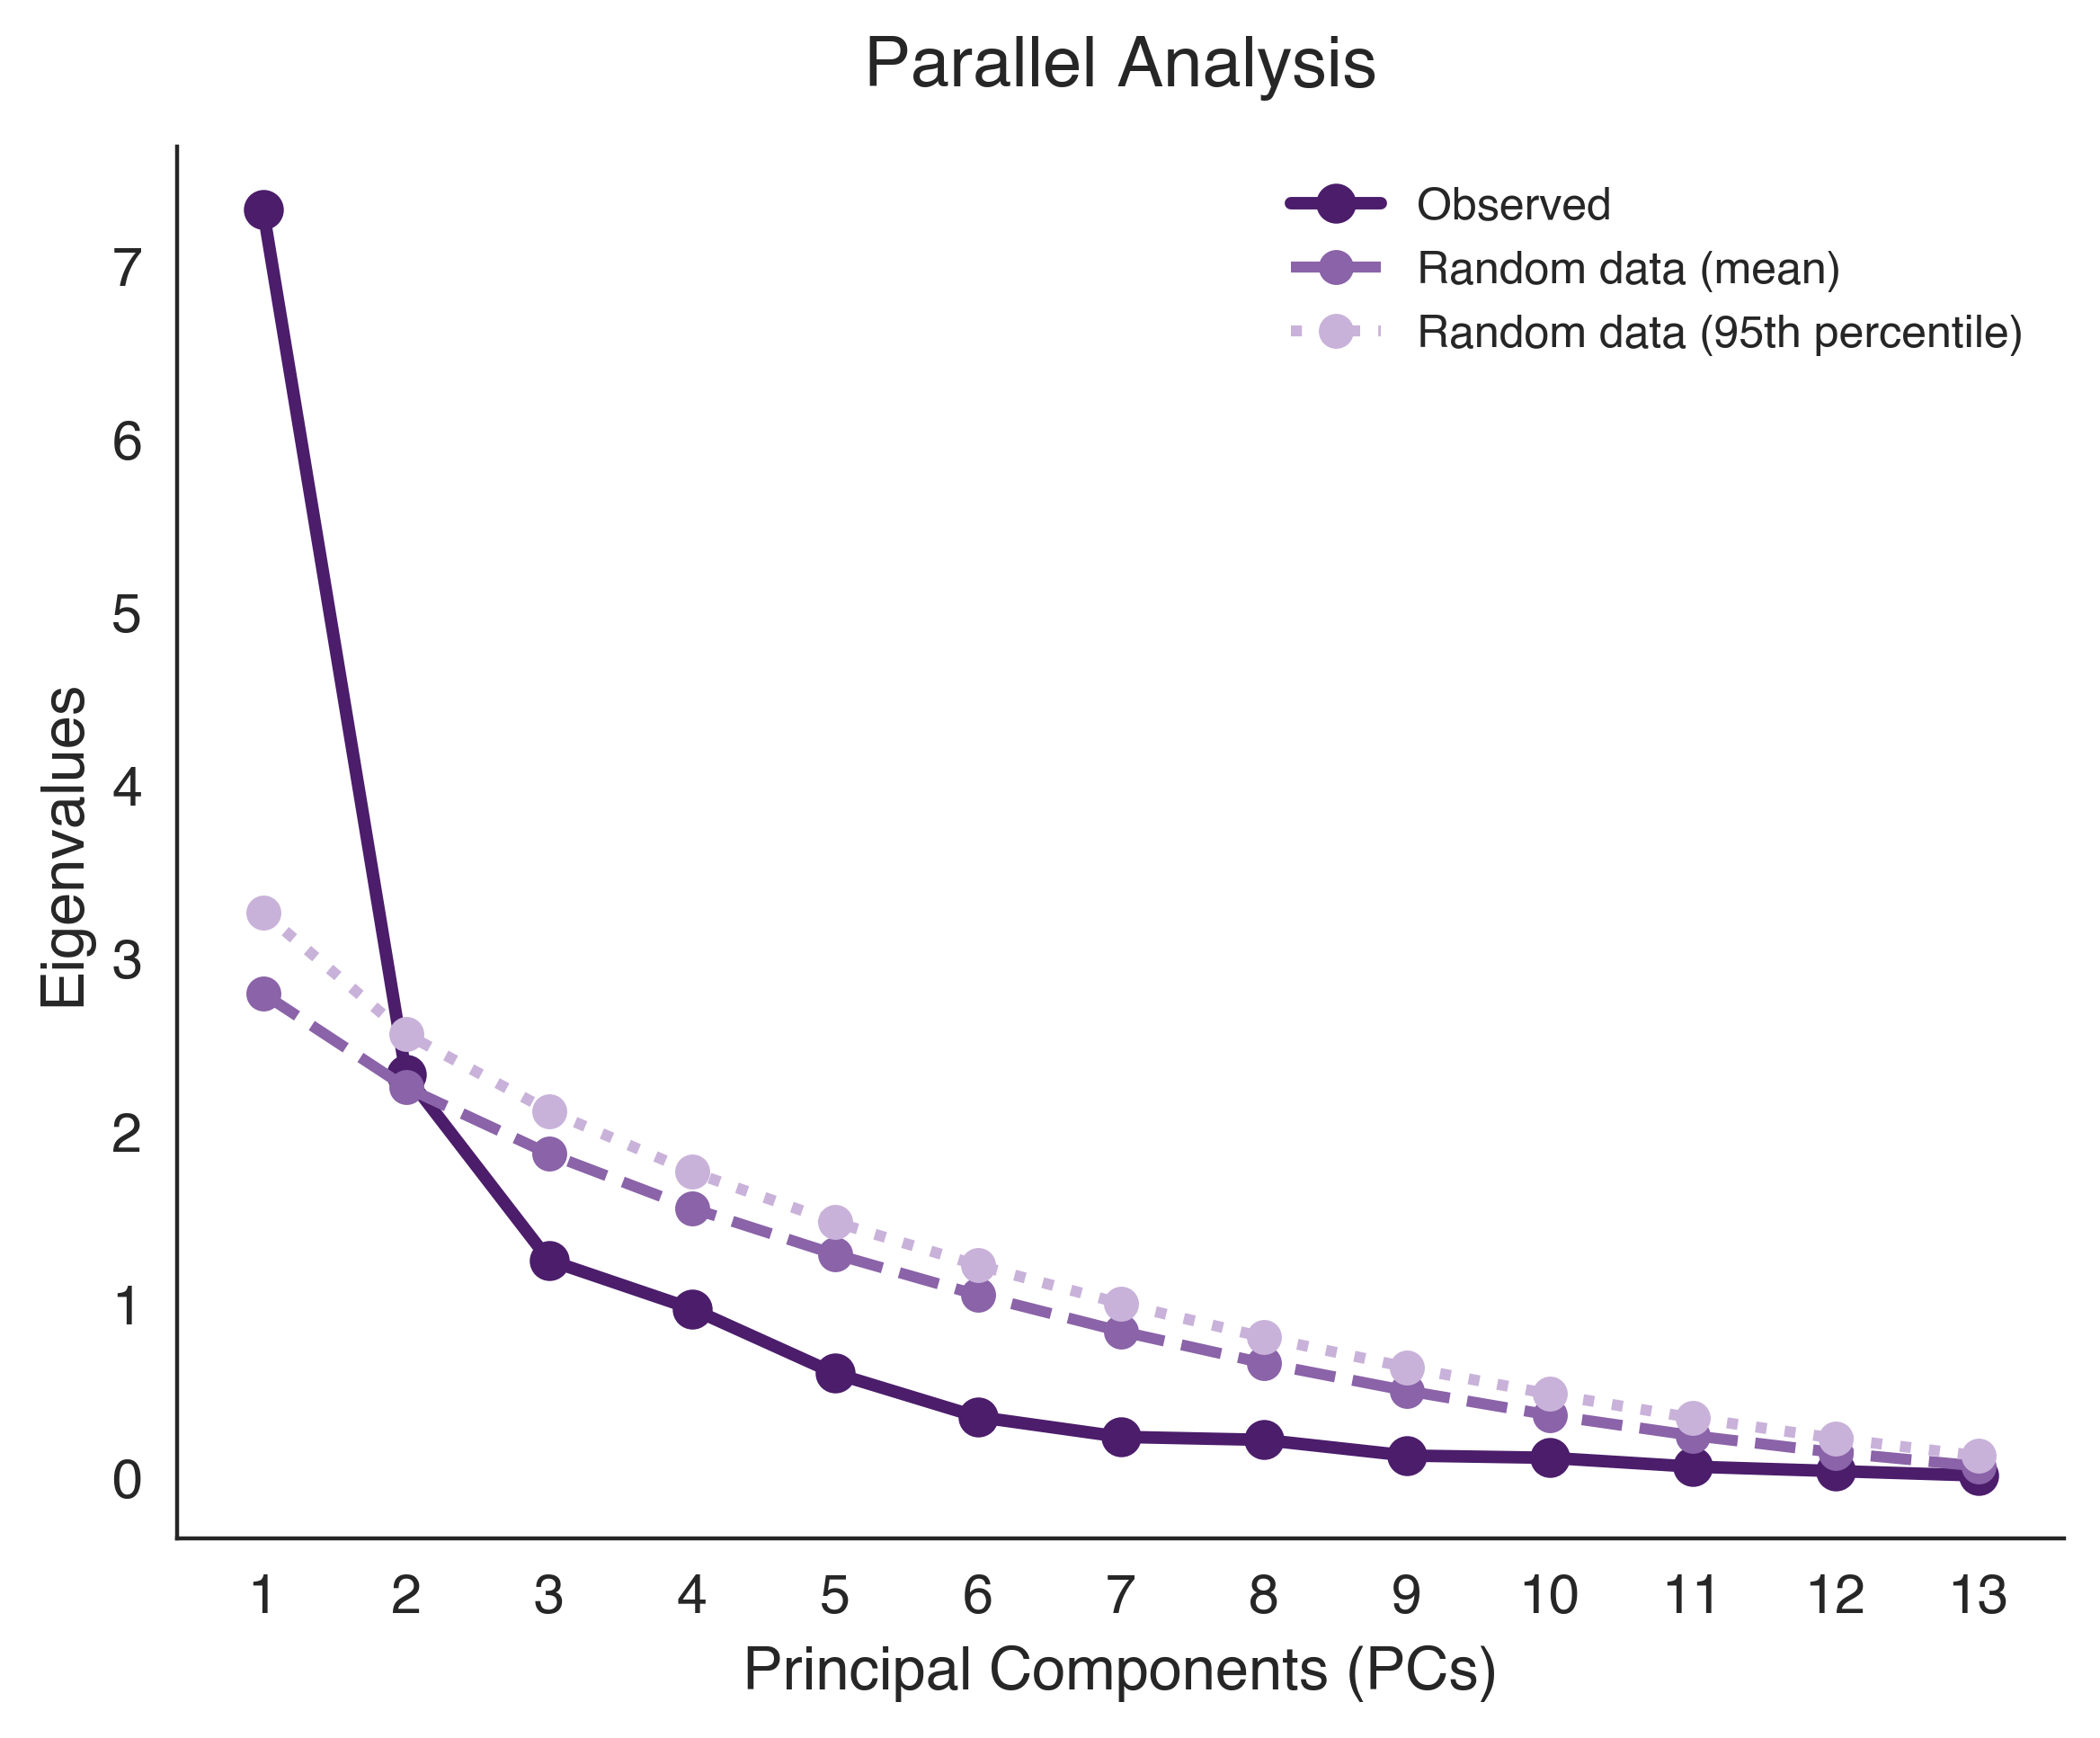


Final number of components retained: 2

RETAINED COMPONENT LOADINGS
                                   PC1    PC2
Population Density              -0.420  0.204
Proficiency Scores              -0.493 -0.750
Unemployment Rate               -0.225  0.843
Gini Coefficient                -0.081  0.933
Childcare Cost Burden            0.584  0.086
Political Preferences            0.927 -0.054
Tightness and Looseness          0.956 -0.072
Incarceration Rate               0.872  0.051
Working Women Index             -0.887  0.189
Women Peace Security Index      -0.911 -0.175
Women Legislator Representation -0.819 -0.151
Abortion Laws                    0.938  0.056
Reproductive Rights Index       -0.899  0.182

------------------------------
PC1
------------------------------
Tightness and Looseness            0.956
Abortion Laws                      0.938
Political Preferences              0.927
Women Peace Security Index        -0.911
Reproductive Rights Index         -0.899
Working Women I

In [54]:
# ============================================================
# PCA OF STATE-LEVEL VARIABLE
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

# ============================================================
# 1. STANDARDIZE VARIABLES
# ============================================================

scaler = StandardScaler()

X = demo
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=X.columns
)

print(f"Number of states: {X.shape[0]}")
print(f"Number of variables: {X.shape[1]}")


# ============================================================
# 2. INITIAL PCA — ALL COMPONENTS
# ============================================================

pca_all = PCA()

pca_all.fit(X_scaled)


# Eigenvalues
eigenvalues = pca_all.explained_variance_


# Percentage of variance explained
variance_explained = (
    pca_all.explained_variance_ratio_ * 100
)


# Cumulative variance explained
cumulative_variance = np.cumsum(
    variance_explained
)


# PCA summary table
summary = pd.DataFrame({
    "PC": [
        f"PC{i+1}"
        for i in range(len(eigenvalues))
    ],

    "Eigenvalue":
        eigenvalues,

    "Variance Explained (%)":
        variance_explained,

    "Cumulative Variance (%)":
        cumulative_variance
})


print("\n==============================")
print("PCA SUMMARY")
print("==============================")

print(
    summary.round(2)
)


# ============================================================
# 3. SCREE PLOT
# ============================================================

plt.rcParams["font.family"] = "Helvetica"

dark_purple = "#4B1D6B"
medium_purple = "#8A63A8"
pale_purple = "#C9B2D9"


fig, ax = plt.subplots(
    figsize=(6, 5)
)


x = np.arange(
    1,
    len(eigenvalues) + 1
)


# Observed eigenvalues
ax.plot(
    x,
    eigenvalues,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color=dark_purple,
    markerfacecolor=dark_purple,
    markeredgecolor=dark_purple
)


# Kaiser eigenvalue = 1 reference line
ax.axhline(
    y=1,
    linestyle="--",
    linewidth=2,
    color=pale_purple,
    label="Eigenvalue = 1"
)


# Labels
ax.set_xlabel(
    "Principal Component",
    fontsize=12
)

ax.set_ylabel(
    "Eigenvalue",
    fontsize=12
)

ax.set_title(
    "Scree Plot",
    fontsize=14,
    pad=12
)


ax.set_xticks(x)


ax.tick_params(
    axis="both",
    labelsize=11
)


# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Legend
ax.legend(
    frameon=False,
    fontsize=10
)


plt.tight_layout()

plt.savefig(
    "/Users/jivesh/Downloads/PCA_scree_plot.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    transparent=False
)

plt.show()


plt.show()


# ============================================================
# 4. PARALLEL ANALYSIS
# ============================================================

n_iter = 5000

n_obs, n_vars = X_scaled.shape


# Reproducibility
rng = np.random.default_rng(
    12345
)


# Store eigenvalues from random datasets
random_eigenvalues = np.zeros(
    (n_iter, n_vars)
)


for i in range(n_iter):

    # --------------------------------------------------------
    # Generate random dataset with same n and p
    # --------------------------------------------------------

    random_data = rng.normal(
        size=(n_obs, n_vars)
    )


    # --------------------------------------------------------
    # Standardize random dataset
    # --------------------------------------------------------

    random_data = (
        StandardScaler()
        .fit_transform(random_data)
    )


    # --------------------------------------------------------
    # PCA of random dataset
    # --------------------------------------------------------

    random_pca = PCA()

    random_pca.fit(
        random_data
    )


    # --------------------------------------------------------
    # Store eigenvalues
    # --------------------------------------------------------

    random_eigenvalues[i, :] = (
        random_pca.explained_variance_
    )


# ============================================================
# 5. RANDOM EIGENVALUE BENCHMARKS
# ============================================================


# Mean eigenvalue across random datasets
random_mean = np.mean(
    random_eigenvalues,
    axis=0
)


# 95th percentile eigenvalue
random_95 = np.percentile(
    random_eigenvalues,
    95,
    axis=0
)


# ============================================================
# 6. PARALLEL ANALYSIS RESULTS TABLE
# ============================================================

parallel_results = pd.DataFrame({

    "PC": [
        f"PC{i+1}"
        for i in range(n_vars)
    ],

    "Observed":
        eigenvalues,

    "Random Mean":
        random_mean,

    "Random 95th":
        random_95,

    "Retain (Mean)":
        eigenvalues > random_mean,

    "Retain (95th)":
        eigenvalues > random_95
})


print("\n==============================")
print("PARALLEL ANALYSIS")
print("==============================")

print(
    parallel_results.round(3)
)


# Number retained under each criterion
n_components_mean = (
    parallel_results[
        "Retain (Mean)"
    ].sum()
)

n_components_95 = (
    parallel_results[
        "Retain (95th)"
    ].sum()
)


print(
    "\nNumber of components retained "
    "using mean random eigenvalues:",
    n_components_mean
)

print(
    "Number of components retained "
    "using 95th-percentile random eigenvalues:",
    n_components_95
)


# ============================================================
# 7. PARALLEL ANALYSIS PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(6, 5)
)


x = np.arange(
    1,
    n_vars + 1
)


# ------------------------------------------------------------
# Observed eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    eigenvalues,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color=dark_purple,
    markerfacecolor=dark_purple,
    markeredgecolor=dark_purple,
    label="Observed"
)


# ------------------------------------------------------------
# Mean random eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    random_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    linestyle="--",
    color=medium_purple,
    markerfacecolor=medium_purple,
    markeredgecolor=medium_purple,
    label="Random data (mean)"
)


# ------------------------------------------------------------
# 95th percentile random eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    random_95,
    marker="o",
    markersize=6,
    linewidth=2.2,
    linestyle=":",
    color=pale_purple,
    markerfacecolor=pale_purple,
    markeredgecolor=pale_purple,
    label="Random data (95th percentile)"
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Principal Components (PCs)",
    fontsize=12
)

ax.set_ylabel(
    "Eigenvalues",
    fontsize=12
)

ax.set_title(
    "Parallel Analysis",
    fontsize=14,
    pad=12
)


ax.set_xticks(x)


ax.tick_params(
    axis="both",
    labelsize=11
)


# Despine
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Legend
ax.legend(
    frameon=False,
    fontsize=9
)


plt.tight_layout()


plt.savefig(
    "/Users/jivesh/Downloads/PCA_parallel_analysis.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    transparent=False
)

plt.show()


# ============================================================
# 8. RETAIN TWO COMPONENTS
# ============================================================
#
# Two components are retained based on consideration of:
#
# 1. Mean parallel analysis
# 2. Variance explained
# 3. Component interpretability
# 4. Leave-one-state-out stability
#
# Note:
# PC2 exceeds the mean random eigenvalue but not the
# more conservative 95th-percentile random eigenvalue.
# ============================================================

n_components = 2


print(
    "\nFinal number of components retained:",
    n_components
)


# ============================================================
# 9. FINAL TWO-COMPONENT PCA
# ============================================================

pca = PCA(
    n_components=n_components
)


PC_scores = pca.fit_transform(
    X_scaled
)


# ============================================================
# 10. PCA LOADINGS
# ============================================================

# Loadings = eigenvectors * sqrt(eigenvalues)

loadings = (
    pca.components_.T *
    np.sqrt(
        pca.explained_variance_
    )
)


loadings_df = pd.DataFrame(
    loadings,

    index=X.columns,

    columns=[
        f"PC{i+1}"
        for i in range(n_components)
    ]
)


print("\n==============================")
print("RETAINED COMPONENT LOADINGS")
print("==============================")

print(
    loadings_df.round(3)
)


# ============================================================
# 11. SORT LOADINGS BY ABSOLUTE MAGNITUDE
# ============================================================

for pc in loadings_df.columns:

    print(
        "\n------------------------------"
    )

    print(pc)

    print(
        "------------------------------"
    )

    sorted_loadings = (
        loadings_df[pc]
        .sort_values(
            key=lambda x: abs(x),
            ascending=False
        )
    )

    print(
        sorted_loadings.round(3)
    )


# ============================================================
# 12. PC1 LOADINGS TABLE
# ============================================================

PC1_loadings = pd.DataFrame({
    "PC1":
        loadings_df["PC1"]
})


PC1_loadings[
    "Absolute Loading"
] = (
    PC1_loadings["PC1"].abs()
)


PC1_loadings = (
    PC1_loadings
    .sort_values(
        "Absolute Loading",
        ascending=False
    )
)


print("\n==============================")
print("PC1 LOADINGS")
print("==============================")

print(
    PC1_loadings.round(3)
)


# ============================================================
# 13. PC2 LOADINGS TABLE
# ============================================================

PC2_loadings = pd.DataFrame({
    "PC2":
        loadings_df["PC2"]
})


PC2_loadings[
    "Absolute Loading"
] = (
    PC2_loadings["PC2"].abs()
)


PC2_loadings = (
    PC2_loadings
    .sort_values(
        "Absolute Loading",
        ascending=False
    )
)


print("\n==============================")
print("PC2 LOADINGS")
print("==============================")

print(
    PC2_loadings.round(3)
)


# ============================================================
# 14. VARIANCE EXPLAINED BY RETAINED COMPONENTS
# ============================================================

print("\n==============================")
print("VARIANCE EXPLAINED")
print("==============================")


for i in range(n_components):

    print(
        f"PC{i+1} explains "
        f"{pca.explained_variance_ratio_[i] * 100:.2f}% "
        "of the total variance."
    )


retained_cumulative_variance = (
    np.sum(
        pca.explained_variance_ratio_
    ) * 100
)


print(
    f"\nPC1 + PC2 explain "
    f"{retained_cumulative_variance:.2f}% "
    "of the total variance."
)


# ============================================================
# 15. STATE PC SCORES
# ============================================================

PC_scores_df = pd.DataFrame(
    PC_scores,

    index=X.index,

    columns=[
        "PC1",
        "PC2"
    ]
)


print("\n==============================")
print("STATE PC SCORES")
print("==============================")

print(
    PC_scores_df.round(3)
)

# ============================================================
# 16. TUCKER'S CONGRUENCE FUNCTION
# ============================================================

def tuckers_congruence(x, y):

    """
    Calculate Tucker's congruence coefficient
    between two loading vectors.
    """

    x = np.asarray(x)
    y = np.asarray(y)

    return (
        np.sum(x * y)
        /
        np.sqrt(
            np.sum(x ** 2)
            *
            np.sum(y ** 2)
        )
    )

# ============================================================
# 17. LEAVE-ONE-STATE-OUT PCA
#     WITH COMPONENT MATCHING
# ============================================================
#
# For each state:
#
# 1. Remove the state
# 2. Re-standardize the remaining states
# 3. Re-run a two-component PCA
# 4. Calculate variance explained
# 5. Compare BOTH leave-one-out components with BOTH
#    full-sample components
# 6. Match components based on Tucker's congruence
# 7. Account for arbitrary PCA sign reversals
# 8. Match variance explained to the corresponding component
#
# This avoids assuming that leave-one-out PC1 must always
# correspond to full-sample PC1.
# ============================================================


# Full-sample PC1 and PC2 loadings
full_PC1 = loadings_df["PC1"].values
full_PC2 = loadings_df["PC2"].values


# Store leave-one-state-out results
stability_results = []


for state in X.index:

    # --------------------------------------------------------
    # Remove one state
    # --------------------------------------------------------

    X_leaveout = X.drop(
        index=state
    )


    # --------------------------------------------------------
    # Re-standardize remaining states
    # --------------------------------------------------------

    X_leaveout_scaled = (
        StandardScaler()
        .fit_transform(
            X_leaveout
        )
    )


    # --------------------------------------------------------
    # Re-run PCA with two components
    # --------------------------------------------------------

    pca_leaveout = PCA(
        n_components=2
    )

    pca_leaveout.fit(
        X_leaveout_scaled
    )


    # --------------------------------------------------------
    # Variance explained in leave-one-state-out PCA
    # --------------------------------------------------------

    leaveout_variance = (
        pca_leaveout.explained_variance_ratio_
        * 100
    )

    leaveout_PC1_variance = (
        leaveout_variance[0]
    )

    leaveout_PC2_variance = (
        leaveout_variance[1]
    )


    # --------------------------------------------------------
    # Calculate leave-one-out loadings
    # --------------------------------------------------------

    leaveout_loadings = (
        pca_leaveout.components_.T
        *
        np.sqrt(
            pca_leaveout.explained_variance_
        )
    )


    leaveout_PC1 = (
        leaveout_loadings[:, 0]
    )

    leaveout_PC2 = (
        leaveout_loadings[:, 1]
    )


    # ========================================================
    # Calculate all pairwise Tucker congruence coefficients
    # ========================================================

    # Full PC1 vs leave-one-out PC1
    congruence_11 = tuckers_congruence(
        full_PC1,
        leaveout_PC1
    )

    # Full PC1 vs leave-one-out PC2
    congruence_12 = tuckers_congruence(
        full_PC1,
        leaveout_PC2
    )

    # Full PC2 vs leave-one-out PC1
    congruence_21 = tuckers_congruence(
        full_PC2,
        leaveout_PC1
    )

    # Full PC2 vs leave-one-out PC2
    congruence_22 = tuckers_congruence(
        full_PC2,
        leaveout_PC2
    )


    # ========================================================
    # Compare the two possible component assignments
    # ========================================================
    #
    # Assignment A:
    #
    # Full PC1 -> leave-out PC1
    # Full PC2 -> leave-out PC2
    #
    # Assignment B:
    #
    # Full PC1 -> leave-out PC2
    # Full PC2 -> leave-out PC1
    #
    # Absolute values are used because PCA signs are arbitrary.
    # ========================================================

    assignment_A = (
        abs(congruence_11)
        +
        abs(congruence_22)
    )

    assignment_B = (
        abs(congruence_12)
        +
        abs(congruence_21)
    )


    # ========================================================
    # Select best component matching
    # ========================================================

    if assignment_A >= assignment_B:

        # Components retain their original order

        matched_PC1 = (
            leaveout_PC1.copy()
        )

        matched_PC2 = (
            leaveout_PC2.copy()
        )

        PC1_congruence_signed = (
            congruence_11
        )

        PC2_congruence_signed = (
            congruence_22
        )

        # Variance explained follows the same matching
        matched_PC1_variance = (
            leaveout_PC1_variance
        )

        matched_PC2_variance = (
            leaveout_PC2_variance
        )

        component_order = "Original"


    else:

        # Components switched order

        matched_PC1 = (
            leaveout_PC2.copy()
        )

        matched_PC2 = (
            leaveout_PC1.copy()
        )

        PC1_congruence_signed = (
            congruence_12
        )

        PC2_congruence_signed = (
            congruence_21
        )

        # Switch variance explained as well
        matched_PC1_variance = (
            leaveout_PC2_variance
        )

        matched_PC2_variance = (
            leaveout_PC1_variance
        )

        component_order = "Switched"


    # ========================================================
    # Correct arbitrary sign reversals
    # ========================================================
    #
    # If Tucker's congruence is negative, multiply the
    # leave-one-out loading vector by -1 so its orientation
    # matches the full-sample component.
    # ========================================================

    if PC1_congruence_signed < 0:

        matched_PC1 = (
            matched_PC1 * -1
        )

        PC1_sign_flipped = True

    else:

        PC1_sign_flipped = False


    if PC2_congruence_signed < 0:

        matched_PC2 = (
            matched_PC2 * -1
        )

        PC2_sign_flipped = True

    else:

        PC2_sign_flipped = False


    # ========================================================
    # Recalculate Tucker congruence after matching/sign
    # alignment
    # ========================================================

    PC1_congruence = tuckers_congruence(
        full_PC1,
        matched_PC1
    )

    PC2_congruence = tuckers_congruence(
        full_PC2,
        matched_PC2
    )


    # ========================================================
    # Combined variance explained
    # ========================================================

    matched_total_variance = (
        matched_PC1_variance
        +
        matched_PC2_variance
    )


    # ========================================================
    # Store results
    # ========================================================

    stability_results.append({

        "State Removed":
            state,

        "PC1 Congruence":
            PC1_congruence,

        "PC2 Congruence":
            PC2_congruence,

        "PC1 Variance Explained (%)":
            matched_PC1_variance,

        "PC2 Variance Explained (%)":
            matched_PC2_variance,

        "PC1 + PC2 Variance Explained (%)":
            matched_total_variance,

        "Component Order":
            component_order,

        "PC1 Sign Flipped":
            PC1_sign_flipped,

        "PC2 Sign Flipped":
            PC2_sign_flipped
    })


# ============================================================
# 18. STABILITY RESULTS
# ============================================================

stability_PC1_PC2 = pd.DataFrame(
    stability_results
)


print("\n========================================")
print("LEAVE-ONE-STATE-OUT PCA STABILITY")
print("========================================")


print(
    stability_PC1_PC2.round(3)
)


# ============================================================
# 19. TUCKER CONGRUENCE SUMMARY
# ============================================================

print("\n========================================")
print("TUCKER CONGRUENCE SUMMARY")
print("========================================")


print(
    stability_PC1_PC2[
        [
            "PC1 Congruence",
            "PC2 Congruence"
        ]
    ]
    .describe()
    .round(3)
)


# ============================================================
# 20. CONGRUENCE RANGES
# ============================================================

PC1_min = (
    stability_PC1_PC2[
        "PC1 Congruence"
    ].min()
)

PC1_max = (
    stability_PC1_PC2[
        "PC1 Congruence"
    ].max()
)


PC2_min = (
    stability_PC1_PC2[
        "PC2 Congruence"
    ].min()
)

PC2_max = (
    stability_PC1_PC2[
        "PC2 Congruence"
    ].max()
)


print(
    f"\nPC1 congruence range: "
    f"{PC1_min:.3f} to {PC1_max:.3f}"
)

print(
    f"PC2 congruence range: "
    f"{PC2_min:.3f} to {PC2_max:.3f}"
)


# ============================================================
# 21. LEAVE-ONE-STATE-OUT VARIANCE EXPLAINED SUMMARY
# ============================================================

variance_cols = [
    "PC1 Variance Explained (%)",
    "PC2 Variance Explained (%)",
    "PC1 + PC2 Variance Explained (%)"
]


variance_summary = pd.DataFrame({

    "Mean (%)":
        stability_PC1_PC2[
            variance_cols
        ].mean(),

    "SD (%)":
        stability_PC1_PC2[
            variance_cols
        ].std(),

    "Min (%)":
        stability_PC1_PC2[
            variance_cols
        ].min(),

    "Max (%)":
        stability_PC1_PC2[
            variance_cols
        ].max()
})


print("\n========================================")
print("LEAVE-ONE-STATE-OUT VARIANCE SUMMARY")
print("========================================")


print(
    variance_summary.round(2)
)


# ============================================================
# 22. PRINT MEAN ± SD VARIANCE EXPLAINED
# ============================================================

PC1_variance_mean = (
    stability_PC1_PC2[
        "PC1 Variance Explained (%)"
    ].mean()
)

PC1_variance_sd = (
    stability_PC1_PC2[
        "PC1 Variance Explained (%)"
    ].std()
)


PC2_variance_mean = (
    stability_PC1_PC2[
        "PC2 Variance Explained (%)"
    ].mean()
)

PC2_variance_sd = (
    stability_PC1_PC2[
        "PC2 Variance Explained (%)"
    ].std()
)


total_variance_mean = (
    stability_PC1_PC2[
        "PC1 + PC2 Variance Explained (%)"
    ].mean()
)

total_variance_sd = (
    stability_PC1_PC2[
        "PC1 + PC2 Variance Explained (%)"
    ].std()
)


print("\n========================================")
print("MEAN ± SD VARIANCE EXPLAINED")
print("========================================")


print(
    f"PC1: "
    f"{PC1_variance_mean:.2f}% ± "
    f"{PC1_variance_sd:.2f}%"
)

print(
    f"PC2: "
    f"{PC2_variance_mean:.2f}% ± "
    f"{PC2_variance_sd:.2f}%"
)

print(
    f"PC1 + PC2: "
    f"{total_variance_mean:.2f}% ± "
    f"{total_variance_sd:.2f}%"
)


# ============================================================
# 23. CHECK FOR COMPONENT SWITCHING
# ============================================================

n_switched = (
    stability_PC1_PC2[
        "Component Order"
    ]
    .eq("Switched")
    .sum()
)


print(
    f"\nNumber of leave-one-state-out solutions "
    f"requiring PC1/PC2 switching: "
    f"{n_switched}"
)


# ============================================================
# 24. CHECK FOR SIGN REVERSALS
# ============================================================

PC1_flips = (
    stability_PC1_PC2[
        "PC1 Sign Flipped"
    ].sum()
)

PC2_flips = (
    stability_PC1_PC2[
        "PC2 Sign Flipped"
    ].sum()
)


print(
    f"PC1 sign reversals corrected: "
    f"{PC1_flips}"
)

print(
    f"PC2 sign reversals corrected: "
    f"{PC2_flips}"
)


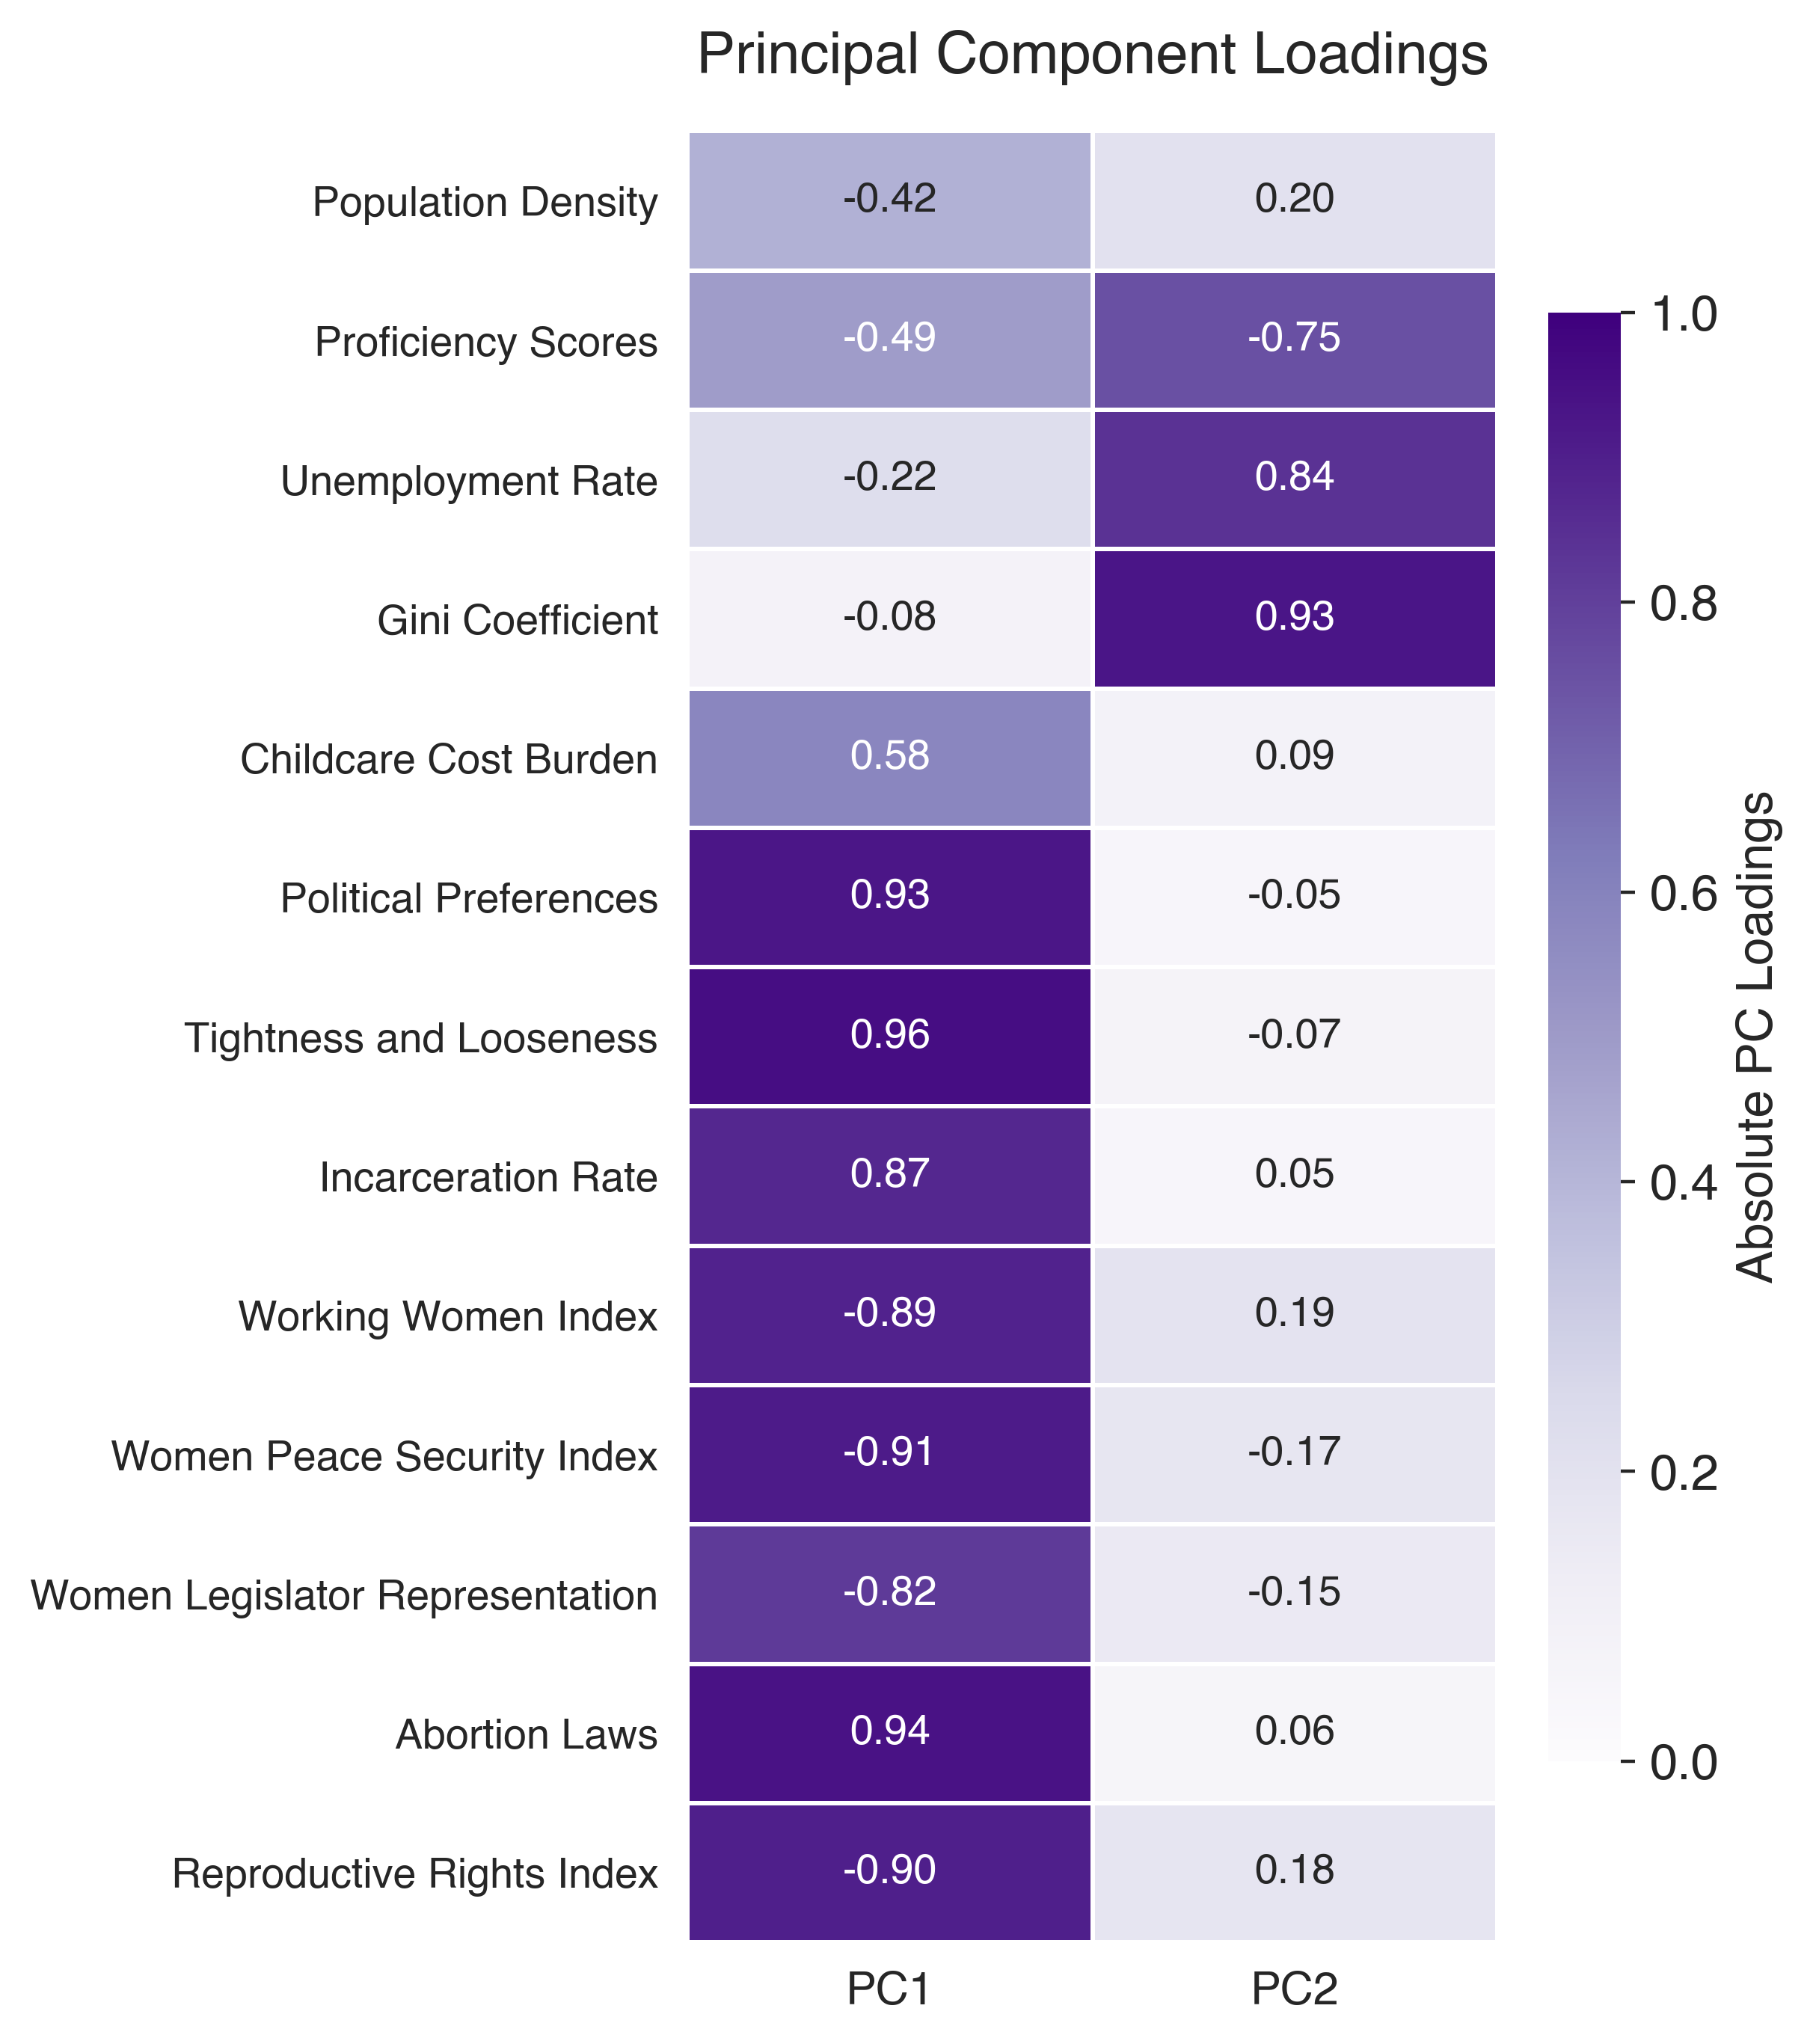

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [40]:
%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

# ============================================================
# PC1 AND PC2 LOADINGS HEATMAP
# ============================================================

# Keep PC1 and PC2
heatmap_data = loadings_df[["PC1", "PC2"]].copy()

# Absolute loadings determine purple intensity
heatmap_abs = heatmap_data.abs()

plt.rcParams["font.family"] = "Helvetica"

fig, ax = plt.subplots(
    figsize=(6, 7),
    facecolor="white"
)

ax.set_facecolor("white")

sns.heatmap(
    heatmap_abs,
    annot=heatmap_data,
    fmt=".2f",
    cmap="Purples",
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={
        "label": "Absolute PC Loadings",
        "shrink": 0.8
    },
    annot_kws={
        "fontsize": 10
    },
    ax=ax
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_title(
    "Principal Component Loadings",
    fontsize=14,
    pad=14
)

ax.set_xticklabels(
    ["PC1", "PC2"],
    fontsize=11,
    rotation=0
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    fontsize=10,
    rotation=0
)

plt.tight_layout()

plt.show()
# Save as PDF (vector graphics)
fig.savefig(
    "PC1_PC2_loadings_heatmap.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [33]:
hbcd_df = pd.read_csv('/Users/jivesh/Downloads/hbcd_data_101826.csv').set_index('participant_id')
hbcd_df.head()


,sed_basic_demographics_gestational_age_delivery,sed_basic_demographics_sex,sed_basic_demographics_child_race,sed_basic_demographics_child_ethnicity,sed_basic_demographics_gestational_age_delivery.1,sed_basic_demographics_rc_mother_education,sed_basic_demographics_recruitment_site,LR_hip_volume,img_mriqc_T1w_candidate_age,img_mriqc_T1w_adjusted_age,...,Association_UncinateFasciculus_dti_fa,ProjectionBasalGanglia_Fornix_dti_fa,Association_Cingulum_md,Association_UncinateFasciculus_md,ProjectionBasalGanglia_Fornix_md,sed_bm_demo_income_002,total_household_size,income_midpoint,pex_bm_apa_apa2_depr_promistscore,substance_use_total
participant_id,,,,,,,,,,,,,,,,,,,,,
sub-8012156453,40,0,0,1,40,1,0,NaN,NaN,NaN,...,0.205835,0.275675,1.241590,1.244700,1.393825,7,3,62499.5,49.4,1
sub-4044959361,40,1,0,1,40,3,0,NaN,NaN,NaN,...,0.231286,0.244577,1.271880,1.242420,1.244890,9,2,149999.5,38.2,1
sub-9656135401,39,0,1,1,39,3,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5,0,29999.5,52.1,3
sub-8573430162,39,1,0,1,39,4,0,1317.120063,0.068,2.0,...,0.207940,0.231695,1.297810,1.309255,1.322240,8,1,87499.5,52.1,3
sub-4495347014,39,1,0,1,39,3,0,NaN,NaN,NaN,...,0.251680,0.279209,1.264175,1.235300,1.348920,10,4,200000.0,38.2,1


In [87]:
site_mapping = {
    0:  ("Arkansas Children's Hospital (site 1)", "Arkansas", "Arkansas Children's Hospital (site 1)"),
    1:  ("Arkansas Children's Hospital (site 2 - UAMS)", "Arkansas", "Arkansas Children's Hospital (site 2 - UAMS)"),
    2:  ("Boston Children's Hospital - Harvard Medical School", "Massachusetts", "Boston Children's Hospital - Harvard Medical School"),
    3:  ("Cedars Sinai (site 1)", "California", "Cedars Sinai"),
    4:  ("Cedars Sinai (site 2 - UCLA)", "California", "Cedars Sinai"),
    5:  ("Children's Hospital Los Angeles", "California", "Children's Hospital Los Angeles"),
    6:  ("Children's Hospital of Philadelphia", "Pennsylvania", "Children's Hospital of Philadelphia"),
    7:  ("Cincinnati Children's Hospital", "Ohio", "Cincinnati Children's Hospital"),
    8:  ("Emory University School of Medicine", "Georgia", "Emory University School of Medicine"),
    9:  ("Johns Hopkins University", "Maryland", "Johns Hopkins University"),
    10: ("New York University", "New York", "New York University"),
    11: ("Northwestern University", "Illinois", "Northwestern University"),
    12: ("Oklahoma State", "Oklahoma", "Oklahoma State"),
    13: ("Oregon Health & Science University", "Oregon", "Oregon Health & Science University"),
    14: ("Pennsylvania State University (site 1 - UP)", "Pennsylvania", "Pennsylvania State University (site 1 - UP)"),
    15: ("Pennsylvania State University (site 2 - COM)", "Pennsylvania", "Pennsylvania State University (site 2 - COM)"),
    16: ("University of Alabama at Birmingham (site 1)", "Alabama", "University of Alabama at Birmingham (site 1)"),
    17: ("University of Alabama at Birmingham (site 2 - UAT)", "Alabama", "University of Alabama at Birmingham (site 2 - UAT)"),
    18: ("University of California San Diego", "California", "University of California San Diego"),
    19: ("University of Florida", "Florida", "University of Florida"),
    20: ("University of Maryland", "Maryland", "University of Maryland"),
    21: ("University of Minnesota", "Minnesota", "University of Minnesota"),
    22: ("University of New Mexico", "New Mexico", "University of New Mexico"),
    23: ("University of North Carolina (site 1)", "North Carolina", "University of North Carolina"),
    24: ("University of North Carolina (site 2 - Wake Forest)", "North Carolina", "University of North Carolina"),
    25: ("University of Vermont", "Vermont", "University of Vermont"),
    26: ("University of Wisconsin", "Wisconsin", "University of Wisconsin"),
    27: ("Vanderbilt University", "Tennessee", "Vanderbilt University"),
    28: ("Washington University in St. Louis", "Missouri", "Washington University in St. Louis"),
    29: ("Virginia Tech", "Virginia", "Virginia Tech")
}

site_lookup = pd.DataFrame.from_dict(
    site_mapping,
    orient="index",
    columns=["site_name", "state", "site_grouped"]
)

site_lookup.index.name = "sed_basic_demographics_recruitment_site"

# Map the three columns to the original DataFrame
site_codes = pd.to_numeric(hbcd_df["sed_basic_demographics_recruitment_site"], errors="coerce")

for col in ["site_name", "state", "site_grouped"]:
    hbcd_df[col] = site_codes.map(site_lookup[col])

# Exclude University of Florida (site 19)
hbcd_df = hbcd_df.loc[site_codes.ne(19)].copy()

# Check number of unique sites and states
print("Original sites:", hbcd_df["sed_basic_demographics_recruitment_site"].nunique())
print("Grouped sites:", hbcd_df["site_grouped"].nunique())
print("States:", hbcd_df["state"].nunique())

hbcd_df.head()


Original sites: 27
Grouped sites: 27
States: 20


,sed_basic_demographics_gestational_age_delivery,sed_basic_demographics_sex,sed_basic_demographics_child_race,sed_basic_demographics_child_ethnicity,sed_basic_demographics_gestational_age_delivery.1,sed_basic_demographics_rc_mother_education,sed_basic_demographics_recruitment_site,LR_hip_volume,img_mriqc_T1w_candidate_age,img_mriqc_T1w_adjusted_age,...,ProjectionBasalGanglia_Fornix_md,sed_bm_demo_income_002,total_household_size,income_midpoint,pex_bm_apa_apa2_depr_promistscore,substance_use_total,site_name,state,site_grouped,region
participant_id,,,,,,,,,,,,,,,,,,,,,
sub-8012156453,40,0,0,1,40,1,0,NaN,NaN,NaN,...,1.393825,7,3,62499.5,49.4,1,Arkansas Children's Hospital (site 1),Arkansas,Arkansas Children's Hospital (site 1),South
sub-4044959361,40,1,0,1,40,3,0,NaN,NaN,NaN,...,1.244890,9,2,149999.5,38.2,1,Arkansas Children's Hospital (site 1),Arkansas,Arkansas Children's Hospital (site 1),South
sub-9656135401,39,0,1,1,39,3,0,NaN,NaN,NaN,...,NaN,5,0,29999.5,52.1,3,Arkansas Children's Hospital (site 1),Arkansas,Arkansas Children's Hospital (site 1),South
sub-8573430162,39,1,0,1,39,4,0,1317.120063,0.068,2.0,...,1.322240,8,1,87499.5,52.1,3,Arkansas Children's Hospital (site 1),Arkansas,Arkansas Children's Hospital (site 1),South
sub-4495347014,39,1,0,1,39,3,0,NaN,NaN,NaN,...,1.348920,10,4,200000.0,38.2,1,Arkansas Children's Hospital (site 1),Arkansas,Arkansas Children's Hospital (site 1),South


In [82]:
state_distribution = pd.DataFrame({"N": hbcd_df["state"].value_counts(), "Percentage": hbcd_df["state"].value_counts(normalize=True) * 100})
state_distribution["Percentage"] = state_distribution["Percentage"].round(2)
state_distribution


,N,Percentage
state,,
California,253,13.54
Pennsylvania,156,8.35
Maryland,113,6.05
Minnesota,111,5.94
Oklahoma,108,5.78
North Carolina,106,5.67
Tennessee,104,5.57
Oregon,101,5.41
Ohio,92,4.93


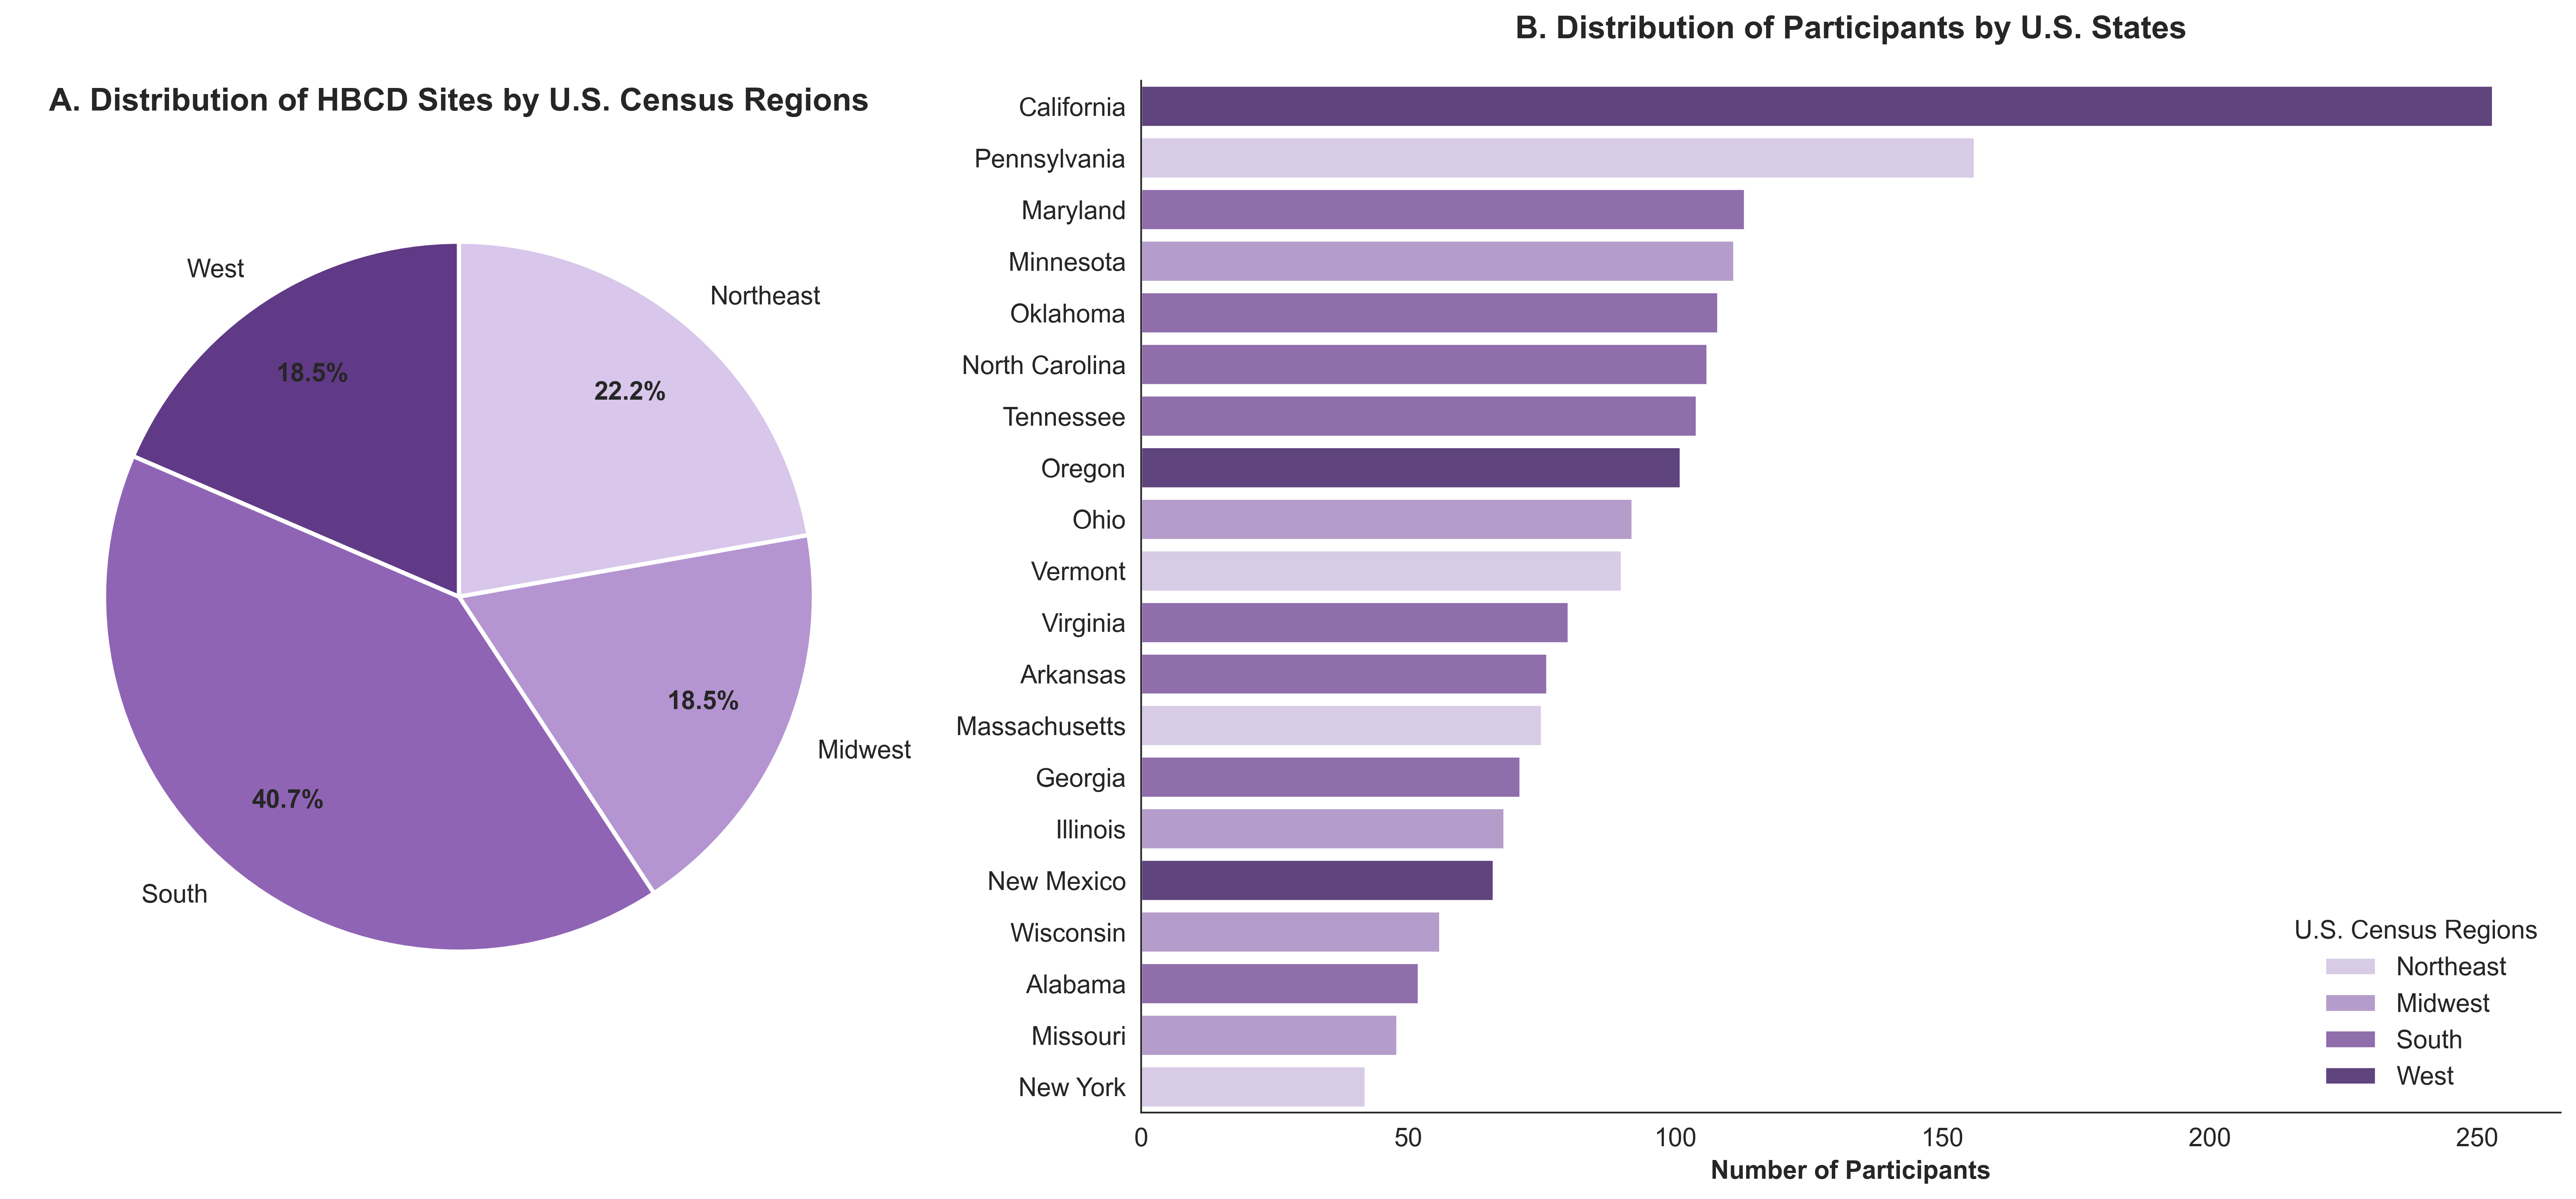

In [83]:
%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

# Map states to U.S. Census regions
region_mapping = {
    # Northeast
    "Massachusetts": "Northeast",
    "New York": "Northeast",
    "Pennsylvania": "Northeast",
    "Vermont": "Northeast",

    # Midwest
    "Illinois": "Midwest",
    "Minnesota": "Midwest",
    "Missouri": "Midwest",
    "Ohio": "Midwest",
    "Wisconsin": "Midwest",

    # South
    "Alabama": "South",
    "Arkansas": "South",
    "Georgia": "South",
    "Maryland": "South",
    "North Carolina": "South",
    "Oklahoma": "South",
    "Tennessee": "South",
    "Virginia": "South",

    # West
    "California": "West",
    "New Mexico": "West",
    "Oregon": "West"
}

# Create region column
hbcd_df["region"] = hbcd_df["state"].map(region_mapping)

# Census region order
region_order = ["Northeast", "Midwest", "South", "West"]

# Purple color palette
region_colors = {
    "Northeast": "#D8C6EB",
    "Midwest": "#B495D2",
    "South": "#9064B5",
    "West": "#603A86"
}

# -----------------------------------
# 1. Count unique sites by region
# -----------------------------------

site_counts = (
    hbcd_df.groupby("region")["site_grouped"]
      .nunique()
      .reindex(region_order, fill_value=0)
)

# -----------------------------------
# 2. Count participants by state
# -----------------------------------

state_counts = (
    hbcd_df.groupby(["region", "state"])
      .size()
      .reset_index(name="N")
      .sort_values("N", ascending=False)
)

# -----------------------------------
# 3. Create figure
# -----------------------------------

sns.set_style("white")

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"width_ratios": [1, 1.6]}
)

# PANEL A: PIE CHART
colors = [region_colors[r] for r in region_order]

wedges, texts, autotexts = axes[0].pie(
    site_counts.values,
    labels=region_order,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%",
    startangle=90,
    counterclock=False,
    pctdistance=0.75,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={"fontsize": 12}
)

for text in autotexts:
    text.set_fontweight("bold")

axes[0].set_title(
    "A. Distribution of HBCD Sites by U.S. Census Regions",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# PANEL B: HORIZONTAL BAR CHART
sns.barplot(
    data=state_counts,
    x="N",
    y="state",
    hue="region",
    hue_order=region_order,
    palette=region_colors,
    dodge=False,
    ax=axes[1]
)

axes[1].set_title(
    "B. Distribution of Participants by U.S. States",
    fontsize=15,
    fontweight="bold",
    pad=20
)

axes[1].set_xlabel(
    "Number of Participants",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_ylabel("")

axes[1].legend(
    title="U.S. Census Regions",
    frameon=False,
    loc="lower right"
)

sns.despine(ax=axes[1])

plt.tight_layout()

# Save high-resolution figure
ax.set_aspect("equal")

# Save as high-resolution PNG
fig.savefig(
    "HBCD_Census_Region_Donut.png",
    dpi=1000,
    bbox_inches="tight",
    facecolor="white"
)

# Save as SVG (vector graphics)
fig.savefig(
    "HBCD_Census_Region_Donut.svg",
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

# Save as PDF (vector graphics)
fig.savefig(
    "HBCD_Census_Region_Donut.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
